## Car Price Prediction Project

### Objective : The goal of this project is to build a machine learning model that predicts the selling price of cars based on their features

### Problem Statement : Used car dealerships and buyers want to estimate the correct resale value of cars. An accurate price prediction system can help both sellers and buyers make better decisions. In this project, you are required to use data preprocessing, exploratory data analysis, and regression modeling to predict car prices.

## Step:1 Data Gathering

In [1]:
import pandas as pd
path = r"D:\ML\DataSets\car_price_prediction.csv"
df = pd.read_csv(path)
df.head()

,ID,Price,Levy,Manufacturer,Model,Prod. year,Category,Leather interior,Fuel type,Engine volume,Mileage,Cylinders,Gear box type,Drive wheels,Doors,Wheel,Color,Airbags
0,45654403,13328,1399,LEXUS,RX 450,2010,Jeep,Yes,Hybrid,3.5,186005 km,6.0,Automatic,4x4,04-May,Left wheel,Silver,12
1,44731507,16621,1018,CHEVROLET,Equinox,2011,Jeep,No,Petrol,3,192000 km,6.0,Tiptronic,4x4,04-May,Left wheel,Black,8
2,45774419,8467,-,HONDA,FIT,2006,Hatchback,No,Petrol,1.3,200000 km,4.0,Variator,Front,04-May,Right-hand drive,Black,2
3,45769185,3607,862,FORD,Escape,2011,Jeep,Yes,Hybrid,2.5,168966 km,4.0,Automatic,4x4,04-May,Left wheel,White,0
4,45809263,11726,446,HONDA,FIT,2014,Hatchback,Yes,Petrol,1.3,91901 km,4.0,Automatic,Front,04-May,Left wheel,Silver,4


## Step : 2 Basic Data Quality Checks

In [2]:
df.shape

(19237, 18)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 19237 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                19237 non-null  int64  
 1   Price             19237 non-null  int64  
 2   Levy              19237 non-null  str    
 3   Manufacturer      19237 non-null  str    
 4   Model             19237 non-null  str    
 5   Prod. year        19237 non-null  int64  
 6   Category          19237 non-null  str    
 7   Leather interior  19237 non-null  str    
 8   Fuel type         19237 non-null  str    
 9   Engine volume     19237 non-null  str    
 10  Mileage           19237 non-null  str    
 11  Cylinders         19237 non-null  float64
 12  Gear box type     19237 non-null  str    
 13  Drive wheels      19237 non-null  str    
 14  Doors             19237 non-null  str    
 15  Wheel             19237 non-null  str    
 16  Color             19237 non-null  str    
 17  Airb

In [4]:
df.isnull().sum()

ID                  0
Price               0
Levy                0
Manufacturer        0
Model               0
Prod. year          0
Category            0
Leather interior    0
Fuel type           0
Engine volume       0
Mileage             0
Cylinders           0
Gear box type       0
Drive wheels        0
Doors               0
Wheel               0
Color               0
Airbags             0
dtype: int64

In [5]:
df.dtypes

ID                    int64
Price                 int64
Levy                    str
Manufacturer            str
Model                   str
Prod. year            int64
Category                str
Leather interior        str
Fuel type               str
Engine volume           str
Mileage                 str
Cylinders           float64
Gear box type           str
Drive wheels            str
Doors                   str
Wheel                   str
Color                   str
Airbags               int64
dtype: object

In [6]:
df.duplicated().sum()

np.int64(313)

In [7]:
df = df.drop_duplicates()

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.shape

(18924, 18)

In [10]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 18 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   ID                18924 non-null  int64  
 1   Price             18924 non-null  int64  
 2   Levy              18924 non-null  str    
 3   Manufacturer      18924 non-null  str    
 4   Model             18924 non-null  str    
 5   Prod. year        18924 non-null  int64  
 6   Category          18924 non-null  str    
 7   Leather interior  18924 non-null  str    
 8   Fuel type         18924 non-null  str    
 9   Engine volume     18924 non-null  str    
 10  Mileage           18924 non-null  str    
 11  Cylinders         18924 non-null  float64
 12  Gear box type     18924 non-null  str    
 13  Drive wheels      18924 non-null  str    
 14  Doors             18924 non-null  str    
 15  Wheel             18924 non-null  str    
 16  Color             18924 non-null  str    
 17  Airbags  

In [11]:
df = pd.get_dummies(df,columns=['Fuel type'],dtype=int) 

In [12]:
updated = []
for i in df['Mileage']:
    data = i.split()
    updated.append(data[0])
updated = list(map(int,updated))
updated

[186005,
 192000,
 200000,
 168966,
 91901,
 160931,
 258909,
 216118,
 398069,
 128500,
 184467,
 0,
 350000,
 138038,
 76000,
 74146,
 121840,
 54317,
 295059,
 364523,
 112645,
 187000,
 39709,
 230000,
 0,
 210000,
 0,
 169000,
 158787,
 420550,
 180000,
 175056,
 200000,
 287274,
 250000,
 162000,
 10200,
 158000,
 103490,
 382746,
 203200,
 61057,
 11200,
 141000,
 160259,
 239342,
 128000,
 100734,
 141500,
 147000,
 87768,
 264014,
 132542,
 1600,
 87000,
 260000,
 5323,
 87112,
 204318,
 22000,
 83000,
 170000,
 312118,
 130000,
 200279,
 719847,
 154672,
 110969,
 225510,
 210000,
 148105,
 255456,
 111643,
 84506,
 288000,
 75000,
 94362,
 175000,
 263190,
 193614,
 264877,
 27656,
 16000,
 0,
 195053,
 121362,
 69191,
 83000,
 40772,
 172000,
 433811,
 350000,
 148213,
 103246,
 105394,
 160000,
 333333,
 0,
 214000,
 123346,
 80827,
 64464,
 91760,
 275240,
 300000,
 318400,
 91200,
 137802,
 151586,
 107000,
 210408,
 100567,
 86000,
 122740,
 144000,
 150000,
 100000,
 1

In [13]:
df['Mileage'] = updated
df['Mileage']

0        186005
1        192000
2        200000
3        168966
4         91901
          ...  
19232    300000
19233    161600
19234    116365
19235     51258
19236    186923
Name: Mileage, Length: 18924, dtype: int64

In [14]:
df.info()

<class 'pandas.DataFrame'>
Index: 18924 entries, 0 to 19236
Data columns (total 24 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   ID                        18924 non-null  int64  
 1   Price                     18924 non-null  int64  
 2   Levy                      18924 non-null  str    
 3   Manufacturer              18924 non-null  str    
 4   Model                     18924 non-null  str    
 5   Prod. year                18924 non-null  int64  
 6   Category                  18924 non-null  str    
 7   Leather interior          18924 non-null  str    
 8   Engine volume             18924 non-null  str    
 9   Mileage                   18924 non-null  int64  
 10  Cylinders                 18924 non-null  float64
 11  Gear box type             18924 non-null  str    
 12  Drive wheels              18924 non-null  str    
 13  Doors                     18924 non-null  str    
 14  Wheel                 

## Step : 3 Exploratory Data Analysis(EDA)

In [15]:
# Descriptive statistics
df.describe().apply(lambda x: x.apply('{:.2f}'.format))

,ID,Price,Prod. year,Mileage,Cylinders,Airbags,Fuel type_CNG,Fuel type_Diesel,Fuel type_Hybrid,Fuel type_Hydrogen,Fuel type_LPG,Fuel type_Petrol,Fuel type_Plug-in Hybrid
count,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00,18924.00
mean,45575381.03,18587.44,2010.91,1555372.72,4.58,6.57,0.02,0.21,0.19,0.00,0.05,0.53,0.00
std,937546.82,192135.63,5.67,48802205.32,1.20,4.32,0.16,0.41,0.39,0.01,0.21,0.50,0.07
min,20746880.00,1.00,1939.00,0.00,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
25%,45695007.50,5331.00,2009.00,70195.75,4.00,4.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00
50%,45771914.50,13172.00,2012.00,126400.00,4.00,6.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
75%,45801742.25,22063.00,2015.00,189119.75,4.00,12.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00
max,45816654.00,26307500.00,2020.00,2147483647.00,16.00,16.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


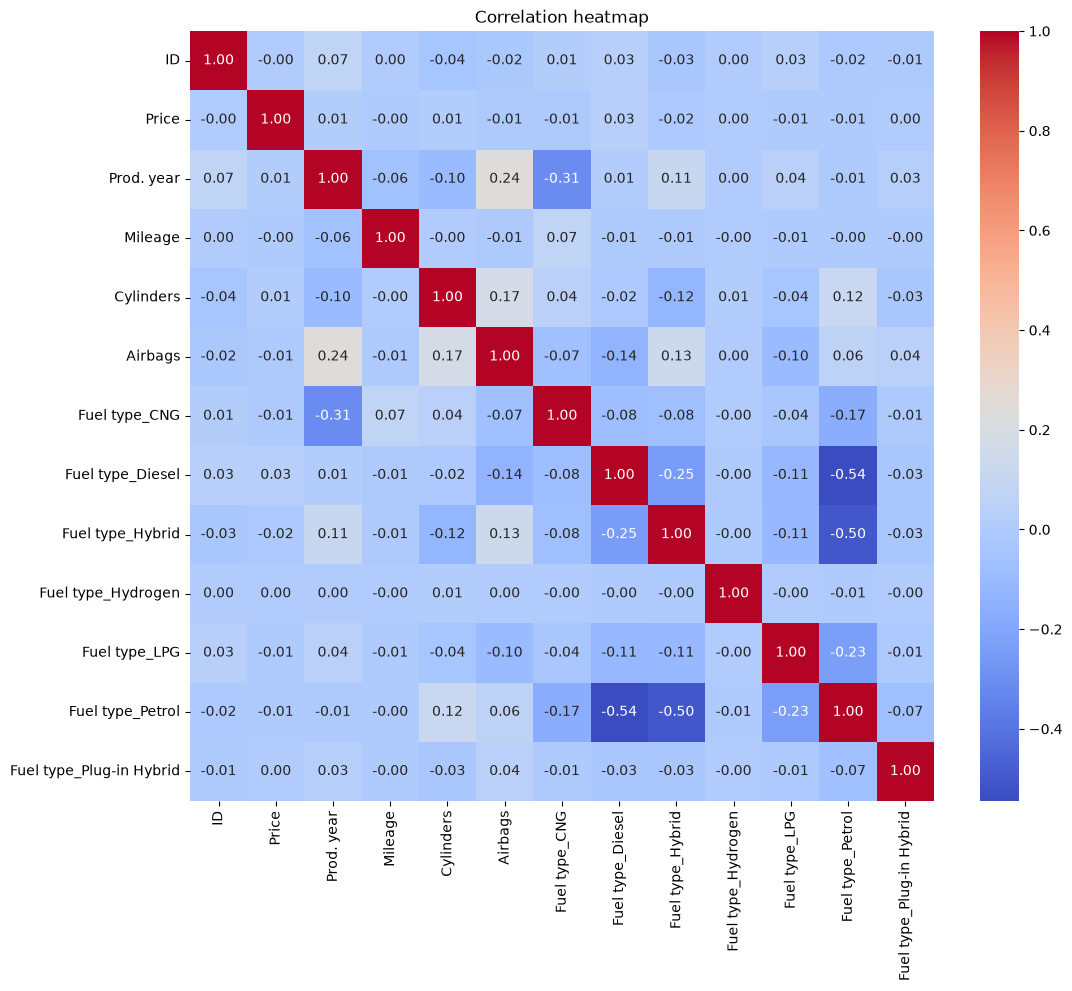

In [16]:
## Correlation 

import seaborn as sns
import matplotlib.pyplot as plt

corr = df.select_dtypes(include="number").corr()
plt.figure(figsize=(12,10))
sns.heatmap(corr,annot=True,cmap="coolwarm",fmt=".2f")
plt.title("Correlation heatmap")
plt.show()


## Analysis
- There is no correlation between the target and independent features 

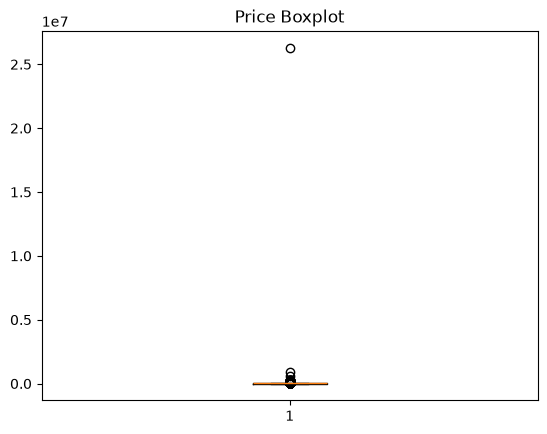

In [17]:
# Boxplot
import matplotlib.pyplot as plt

plt.boxplot(df["Price"])
plt.title("Price Boxplot")
plt.show()

## Analysis
- Outliers: Several outliers are present.

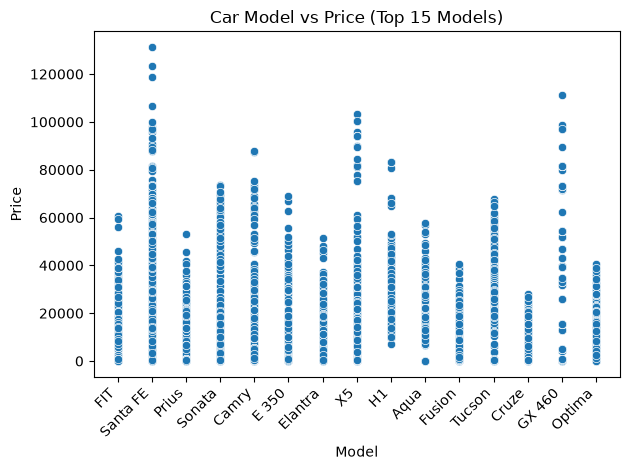

In [18]:
## Scatter plot
import seaborn as sns
import matplotlib.pyplot as plt

top_models = df["Model"].value_counts().head(15).index

data = df[df["Model"].isin(top_models)]

sns.scatterplot(data=data, x="Model", y="Price")

plt.xticks(rotation=45, ha="right")
plt.title("Car Model vs Price (Top 15 Models)")
plt.tight_layout()
plt.show()


## Analysis
- There is no relationship between the features due to spread of datapoints 

In [ ]:
# Clean levy and Engine Value
import pandas as pd
import numpy as np

# Clean Levy
df["Levy"] = df["Levy"].replace("-", np.nan)
df["Levy"] = pd.to_numeric(df["Levy"], errors="coerce")

# Clean Engine volume
df["Engine volume"] = (
    df["Engine volume"]
    .str.replace(" Turbo", "", regex=False)
)

df["Engine volume"] = pd.to_numeric(
    df["Engine volume"], errors="coerce"
)

print(df[["Levy", "Engine volume"]].dtypes)
print(df[["Levy", "Engine volume"]].isnull().sum())